# Climatology check
Test climatology from `make_clm.py` on the ROMS grid: maps and sections for sharing on GitHub.
Change the settings in the first cell, then run all cells.

In [1]:
import glob
import numpy as np
import xarray as xr
import xroms
import matplotlib.pyplot as plt

# ---- settings ----
DIR  = "/scratch/nn411/clm_test/roms_ready"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"
FIGS = "/home/nn411/Projects/OceanAtm/Moana-2.0/Figures"
IT   = 4          # record: 0 = 31 Dec 00:00, 4 = 1 Jan 00:00, 20 = 5 Jan 00:00
LAT  = -40.0      # latitude of the sections

## Load the grid and the five climatology files

In [2]:
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)          # depth of every s-level
lon, lat, z = g.lon_rho.values % 360, g.lat_rho.values, grid.z_rho.values
ocean = g.mask_rho.values == 1
mask = lambda a: np.where(ocean, a, np.nan)            # hide land


def load(var):
    """One record of clm_<var>, plus a summary line."""
    ds = xr.open_dataset(glob.glob(f"{DIR}/clm_{var}_*.nc")[0], decode_times=False)
    tname = ds[var].attrs["time"]
    t = ds[tname].values
    print(f"clm_{var:5s} {str(ds[var].dims):45s} {len(t)} records, {t[0]:.2f} to {t[-1]:.2f} days")
    return ds[var].isel({tname: IT}).values, float(t[IT])


temp, day = load("temp")
salt, _ = load("salt")
zeta, _ = load("zeta")
u, _ = load("u")
v, _ = load("v")
print(f"\nPlotting record {IT}: {day:.2f} days since 2026-01-01")

clm_temp  ('temp_time', 's_rho', 'eta_rho', 'xi_rho')   21 records, -1.00 to 4.00 days
clm_salt  ('salt_time', 's_rho', 'eta_rho', 'xi_rho')   21 records, -1.00 to 4.00 days
clm_zeta  ('zeta_time', 'eta_rho', 'xi_rho')            21 records, -1.00 to 4.00 days
clm_u     ('v3d_time', 's_rho', 'eta_u', 'xi_u')        21 records, -1.00 to 4.00 days
clm_v     ('v3d_time', 's_rho', 'eta_v', 'xi_v')        21 records, -1.00 to 4.00 days

Plotting record 4: 0.00 days since 2026-01-01


## Surface maps
Temperature, salinity, sea surface height and current speed. u and v are averaged onto the cell centres for the speed.

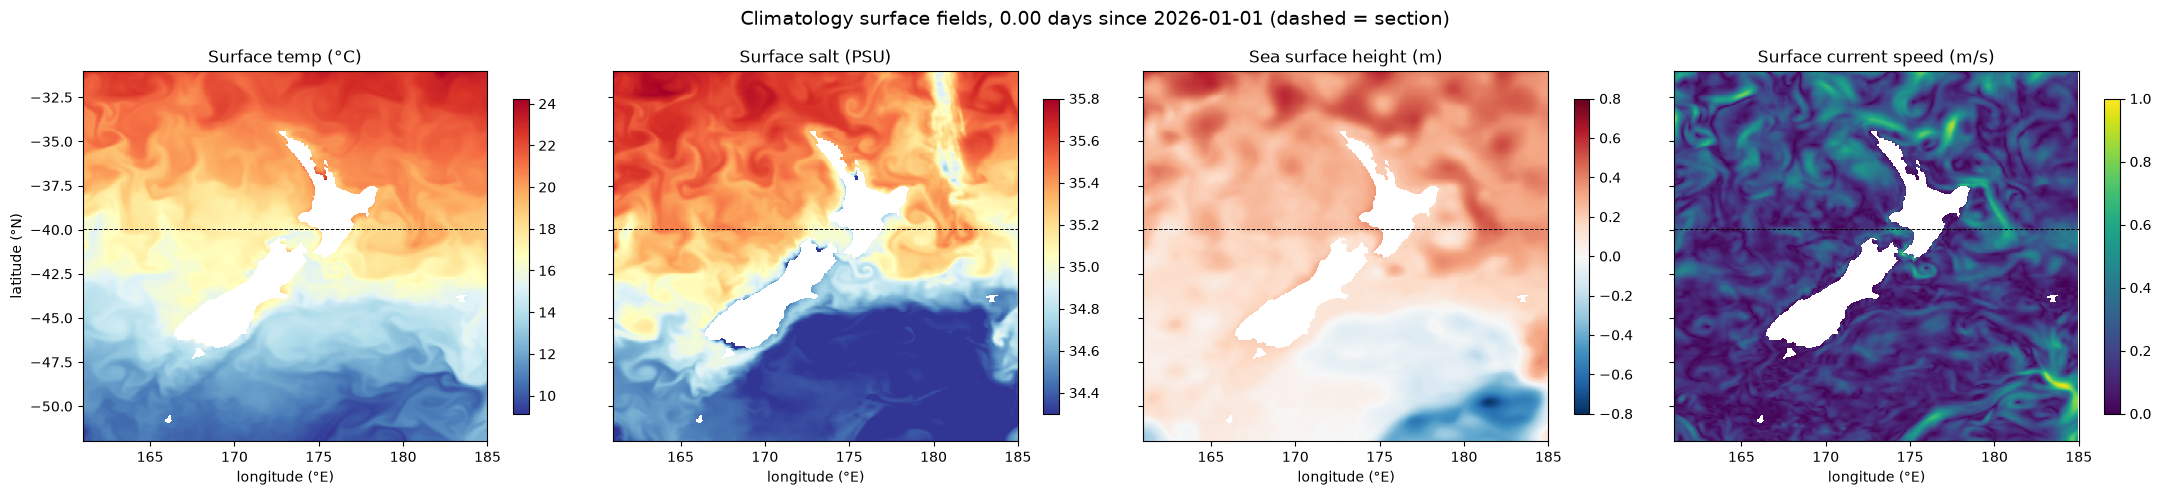

In [3]:
uc = 0.5 * (u[-1, 1:-1, :-1] + u[-1, 1:-1, 1:])
vc = 0.5 * (v[-1, :-1, 1:-1] + v[-1, 1:, 1:-1])
speed = np.full(lon.shape, np.nan)
speed[1:-1, 1:-1] = np.hypot(uc, vc)
row = int(np.argmin(abs(lat[:, 0] - LAT)))

maps = [(temp[-1], "Surface temp (°C)", "RdYlBu_r", None, None),
        (salt[-1], "Surface salt (PSU)", "RdYlBu_r", 34.3, 35.8),
        (zeta, "Sea surface height (m)", "RdBu_r", -0.8, 0.8),
        (speed, "Surface current speed (m/s)", "viridis", 0, 1)]

fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
for ax, (field, title, cmap, vmin, vmax) in zip(axes, maps):
    pc = ax.pcolormesh(lon, lat, mask(field), cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    ax.axhline(lat[row, 0], color="k", ls="--", lw=0.7)      # where the sections are
    fig.colorbar(pc, ax=ax, shrink=0.85)
    ax.set_title(title)
    ax.set_xlabel("longitude (°E)")
axes[0].set_ylabel("latitude (°N)")
fig.suptitle(f"Climatology surface fields, {day:.2f} days since 2026-01-01 (dashed = section)", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIGS}/clm_surface_maps.png", dpi=130, bbox_inches="tight")
plt.show()

## Sections
Temperature and salinity with depth along the dashed line.

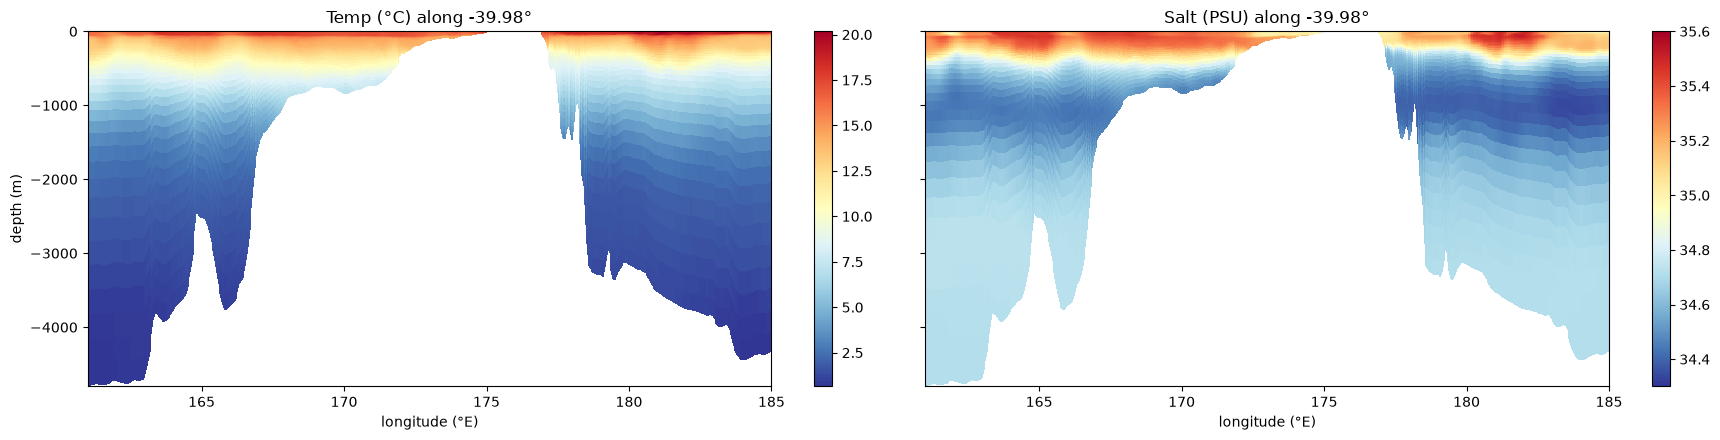

In [4]:
xs = np.broadcast_to(lon[row], z[:, row].shape)

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), sharey=True)
for ax, (field, title, vmin, vmax) in zip(axes, [(temp, "Temp (°C)", None, None),
                                                 (salt, "Salt (PSU)", 34.3, 35.6)]):
    pc = ax.pcolormesh(xs, z[:, row], np.where(ocean[row], field[:, row], np.nan),
                       cmap="RdYlBu_r", vmin=vmin, vmax=vmax, shading="auto")
    fig.colorbar(pc, ax=ax)
    ax.set_title(f"{title} along {lat[row, 0]:.2f}°")
    ax.set_xlabel("longitude (°E)")
axes[0].set_ylabel("depth (m)")
plt.tight_layout()
plt.savefig(f"{FIGS}/clm_sections.png", dpi=130, bbox_inches="tight")
plt.show()

In [5]:
import glob

DIR = "/scratch/nn411/clm_test/roms_ready"
times = {}
for var in ["u", "v", "temp", "salt", "zeta"]:
    ds = xr.open_dataset(glob.glob(f"{DIR}/clm_{var}_*.nc")[0], decode_times=False)
    t = ds[ds[var].attrs["time"]].values
    times[var] = t
    steps_h = np.unique(np.round(np.diff(t) * 24, 3))
    print(f"clm_{var:5s} {len(t)} records, {t[0]:+.2f} to {t[-1]:+.2f} days, spacing (h): {steps_h}")

clm_u     21 records, -1.00 to +4.00 days, spacing (h): [6.]
clm_v     21 records, -1.00 to +4.00 days, spacing (h): [6.]
clm_temp  21 records, -1.00 to +4.00 days, spacing (h): [6.]
clm_salt  21 records, -1.00 to +4.00 days, spacing (h): [6.]
clm_zeta  21 records, -1.00 to +4.00 days, spacing (h): [6.]


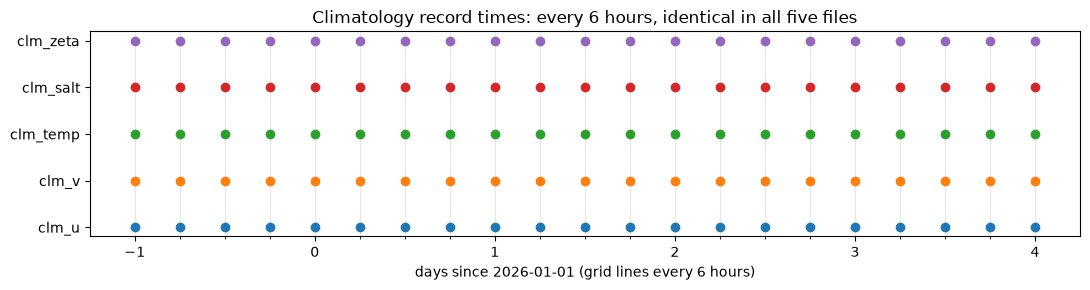

In [6]:
fig, ax = plt.subplots(figsize=(11, 3))
for k, (var, t) in enumerate(times.items()):
    ax.plot(t, np.full(len(t), k), "o", ms=6)
ax.set_yticks(range(len(times)), [f"clm_{v}" for v in times])
ax.set_xticks(np.arange(-1, 4.01, 0.25), minor=True)
ax.grid(axis="x", which="both", alpha=0.3)
ax.set_xlabel("days since 2026-01-01 (grid lines every 6 hours)")
ax.set_title("Climatology record times: every 6 hours, identical in all five files")
plt.tight_layout()
plt.show()

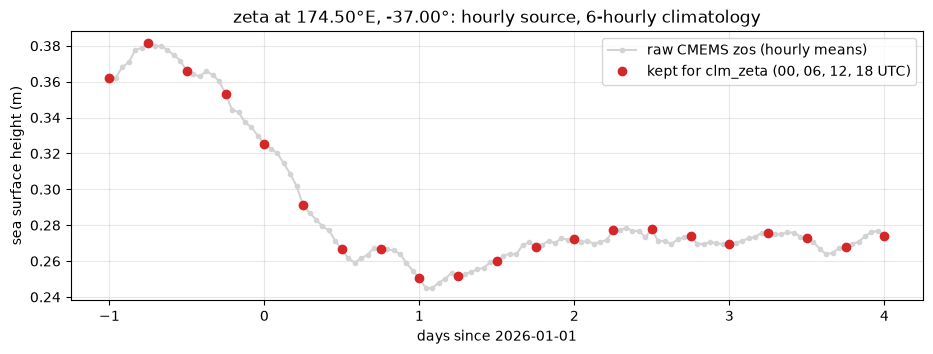

In [7]:
z = xr.open_mfdataset("/scratch/nn411/clm_test/raw/zos_raw_*.nc", combine="nested", concat_dim="time")
z = z.drop_duplicates("time").isel(elevation=0)
pt = z.zos.sel(longitude=174.5, latitude=-37.0, method="nearest")
hourly_days = (pt.time.values - np.datetime64("2026-01-01")) / np.timedelta64(1, "D")
kept = (pt.time.dt.hour % 6 == 0).values

plt.figure(figsize=(11, 3.5))
plt.plot(hourly_days, pt, ".-", color="lightgray", label="raw CMEMS zos (hourly means)")
plt.plot(hourly_days[kept], pt.values[kept], "o", color="C3", label="kept for clm_zeta (00, 06, 12, 18 UTC)")
plt.xlabel("days since 2026-01-01"); plt.ylabel("sea surface height (m)")
plt.title(f"zeta at {float(pt.longitude):.2f}°E, {float(pt.latitude):.2f}°: hourly source, 6-hourly climatology")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [1]:
import pandas as pd

In [25]:
start = "2026-01-01"
end =  "2026-01-31"
CHUNK = "0.25D"
t0 = pd.Timestamp(start) - pd.Timedelta("1D")
t1 = pd.Timestamp(end) + pd.Timedelta("2D")
edges = list(pd.date_range(t0, t1, freq=CHUNK))


In [26]:
edges

[Timestamp('2025-12-31 00:00:00'),
 Timestamp('2025-12-31 06:00:00'),
 Timestamp('2025-12-31 12:00:00'),
 Timestamp('2025-12-31 18:00:00'),
 Timestamp('2026-01-01 00:00:00'),
 Timestamp('2026-01-01 06:00:00'),
 Timestamp('2026-01-01 12:00:00'),
 Timestamp('2026-01-01 18:00:00'),
 Timestamp('2026-01-02 00:00:00'),
 Timestamp('2026-01-02 06:00:00'),
 Timestamp('2026-01-02 12:00:00'),
 Timestamp('2026-01-02 18:00:00'),
 Timestamp('2026-01-03 00:00:00'),
 Timestamp('2026-01-03 06:00:00'),
 Timestamp('2026-01-03 12:00:00'),
 Timestamp('2026-01-03 18:00:00'),
 Timestamp('2026-01-04 00:00:00'),
 Timestamp('2026-01-04 06:00:00'),
 Timestamp('2026-01-04 12:00:00'),
 Timestamp('2026-01-04 18:00:00'),
 Timestamp('2026-01-05 00:00:00'),
 Timestamp('2026-01-05 06:00:00'),
 Timestamp('2026-01-05 12:00:00'),
 Timestamp('2026-01-05 18:00:00'),
 Timestamp('2026-01-06 00:00:00'),
 Timestamp('2026-01-06 06:00:00'),
 Timestamp('2026-01-06 12:00:00'),
 Timestamp('2026-01-06 18:00:00'),
 Timestamp('2026-01-

In [23]:
for a, b in zip(edges[:-1], edges[1:]):
            print(a)
           

2026-01-01 00:00:00
2026-01-01 06:00:00
2026-01-01 12:00:00
2026-01-01 18:00:00
2026-01-02 00:00:00
2026-01-02 06:00:00
2026-01-02 12:00:00
2026-01-02 18:00:00
2026-01-03 00:00:00
2026-01-03 06:00:00
2026-01-03 12:00:00
2026-01-03 18:00:00
2026-01-04 00:00:00
2026-01-04 06:00:00
2026-01-04 12:00:00
2026-01-04 18:00:00
2026-01-05 00:00:00
2026-01-05 06:00:00
2026-01-05 12:00:00
2026-01-05 18:00:00
2026-01-06 00:00:00
2026-01-06 06:00:00
2026-01-06 12:00:00
2026-01-06 18:00:00
2026-01-07 00:00:00
2026-01-07 06:00:00
2026-01-07 12:00:00
2026-01-07 18:00:00
2026-01-08 00:00:00
2026-01-08 06:00:00
2026-01-08 12:00:00
2026-01-08 18:00:00
2026-01-09 00:00:00
2026-01-09 06:00:00
2026-01-09 12:00:00
2026-01-09 18:00:00
2026-01-10 00:00:00
2026-01-10 06:00:00
2026-01-10 12:00:00
2026-01-10 18:00:00
2026-01-11 00:00:00
2026-01-11 06:00:00
2026-01-11 12:00:00
2026-01-11 18:00:00
2026-01-12 00:00:00
2026-01-12 06:00:00
2026-01-12 12:00:00
2026-01-12 18:00:00
2026-01-13 00:00:00
2026-01-13 06:00:00
